# Part III: Train Muse Glimmer to be the router

**Building Specialized Intelligence on Fireworks: From Inference to Training with Muse Open Models**
Meta Global Hackathon workshop, Sinan Ozdemir (Fireworks)

In Part II we built a router by hand: measure, make a table, put a classifier in front. Here we **train a model to make the decision itself**.

- **Model:** Muse Glimmer 30B, LoRA SFT. **Free to train until November 30, 2026** (Serverless Training API, no credit card).
- **Data:** public [SupraLabs/Prompt-Routing-Dataset](https://huggingface.co/datasets/SupraLabs/Prompt-Routing-Dataset) on Hugging Face (992 prompts; we train on 600). Given a user prompt, the model returns a compact JSON object: `complexity` (1-5), `math`, `code`, `reasoning`, and `route` (`"small model"` or `"big model"`).
- **Surface:** **Serverless Training only** (no Fireworks dataset upload). Your Python process builds chat JSONL from Hugging Face, runs the LoRA loop on the shared pool, samples base and tuned on held-out rows, and promotes the LoRA. Managed SFT needs `datasets.upload`, which is currently disabled on many accounts.
- **Use it:** deploy the tuned LoRA and send real prompts to DeepSeek V4.1 Flash (small) and Muse Spark Open (big).

Docs: [Cookbook: Muse Glimmer First Fine-Tune](https://docs.fireworks.ai/fine-tuning/training-api/cookbook/muse-glimmer)


## Setup

You need Git, Python 3.11+, a Fireworks API key and, for deployment, [`firectl`](https://docs.fireworks.ai/tools-sdks/firectl/firectl).

```bash
FIREWORKS_API_KEY=fw_...
FIREWORKS_ACCOUNT_ID=your-account-id
```

The free promotion covers **LoRA SFT jobs started before 2026-12-01 00:00 PT**. It does not cover RL, DPO, full-parameter training, deployments, or sampling outside the training run. The Serverless path samples about 80 answers to compare base and tuned; that sampling is billed at normal per-token rates, and `launch` prints the cost.

This notebook never calls `datasets.upload`. Data stays local (built from Hugging Face) and is streamed by the Serverless Training client.


In [1]:
# Clone and install the cookbook once.
import os, subprocess, sys
from pathlib import Path

COOKBOOK = Path("cookbook")
if not COOKBOOK.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/fw-ai/cookbook.git"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(COOKBOOK / "training")], check=True)
# Current cookbook pins transformers==5.10.4 and no longer needs tinker-cookbook.
# Drop any leftover install that still requires transformers<=5.5.4.
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "tinker-cookbook"], check=False)
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "transformers==5.10.4",
     "openai", "python-dotenv", "pandas", "matplotlib", "datasets"],
    check=True,
)
print("cookbook ready")

cookbook ready


In [2]:
import json, re, time
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from fireworks import Fireworks
from IPython.display import display
from openai import OpenAI

repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists()), Path.cwd())
load_dotenv(repo_root / ".env", override=True)
FIREWORKS_API_KEY = os.environ.get("FIREWORKS_API_KEY")
assert FIREWORKS_API_KEY, "Set FIREWORKS_API_KEY"

# Bind to the account the API key actually belongs to (needed for LoRA promote).
_probe = Fireworks(timeout=60)
_key_account = next(iter(_probe.accounts.list(page_size=1)), None)
assert _key_account is not None, "API key could not list any account"
KEY_ACCOUNT_ID = _key_account.name.split("/")[-1]
KEY_ACCOUNT_DISPLAY = getattr(_key_account, "display_name", KEY_ACCOUNT_ID) or KEY_ACCOUNT_ID
ACCOUNT_ID = os.environ.get("FIREWORKS_ACCOUNT_ID") or KEY_ACCOUNT_ID
if ACCOUNT_ID != KEY_ACCOUNT_ID:
    print(
        f"note: FIREWORKS_ACCOUNT_ID={ACCOUNT_ID!r} differs from key account "
        f"{KEY_ACCOUNT_ID!r} ({KEY_ACCOUNT_DISPLAY}); using key account for promote"
    )
    ACCOUNT_ID = KEY_ACCOUNT_ID
os.environ["FIREWORKS_ACCOUNT_ID"] = ACCOUNT_ID
fw = Fireworks(account_id=ACCOUNT_ID, timeout=120)
print("control plane:", os.getenv("FIREWORKS_BASE_URL", "https://api.fireworks.ai"), "| account:", ACCOUNT_ID)

BASE_MODEL = "accounts/fireworks/models/muse-glimmer-30b"

TRAINING_DIR = COOKBOOK / "training"
STARTER = "examples.sft.muse_glimmer_starter"
ENV = {**os.environ, "FIREWORKS_API_KEY": FIREWORKS_API_KEY, "FIREWORKS_ACCOUNT_ID": ACCOUNT_ID}

def sh(args, cwd=TRAINING_DIR, check=True):
    """Run a command and stream its output into the notebook."""
    shown = list(map(str, args))
    for i, a in enumerate(shown):
        if a in ("--api-key", "-k") and i + 1 < len(shown):
            shown[i + 1] = "***"
        if a.startswith("fw_"):
            shown[i] = "***"
    print("$", " ".join(shown))
    p = subprocess.Popen(list(map(str, args)), cwd=cwd, env=ENV, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, bufsize=1)
    lines = []
    for line in p.stdout:
        print(line, end="")
        lines.append(line)
    p.wait()
    if check and p.returncode != 0:
        raise RuntimeError(f"command failed ({p.returncode})")
    return "".join(lines)

def starter(*args, check=True):
    return sh([sys.executable, "-m", STARTER, *args], check=check)

def firectl(*args, check=True):
    """firectl with API-key auth (avoids stale Cognito oauth2 invalid_grant)."""
    return sh(
        ["firectl", "-a", ACCOUNT_ID, "--api-key", FIREWORKS_API_KEY, *args],
        cwd=None,
        check=check,
    )

print("helpers ready (serverless path; no dataset upload)")


control plane: https://api.fireworks.ai | account: pyroworks
helpers ready (serverless path; no dataset upload)


## Step 1: Build the data from Hugging Face (local only)

Same recipe as the cookbook's [`sft_prompt_router`](https://github.com/fw-ai/cookbook/tree/main/training/case-studies/sft_prompt_router) case study: load `SupraLabs/Prompt-Routing-Dataset`, shuffle with seed 0, keep 600 rows for training (the Serverless step holds 40 of them out for the base-vs-tuned eval) and the next 60 as an extra untouched holdout. Each row becomes `[system, user, assistant]` chat JSONL, with the label as compact JSON.

Nothing is uploaded to Fireworks. Serverless Training reads this file from disk in your process.

The labels follow one rule: `complexity >= 3` OR code OR math → big model. The system prompt gives the schema but **not** the rule, so the model has to learn the policy from the examples. The cookbook's prompt ends with `/no_think` for Qwen; that's dropped here for Muse Glimmer.


In [3]:
from datasets import load_dataset

HF_DATASET = "SupraLabs/Prompt-Routing-Dataset"
N_TRAIN, N_EXTRA_EVAL, SEED = 600, 60, 0

# System prompt from the cookbook's sft_prompt_router case study (schema only, no rule).
ROUTER_SYSTEM = (
    "You are a prompt-routing classifier for an LLM serving stack. Given a user prompt, "
    "analyze the task and decide whether a small local model can handle it or whether it "
    "must be escalated to a big frontier model.\n\n"
    "Respond with ONLY a compact JSON object (no prose, no code fence) with exactly these "
    "keys, in this order:\n"
    '- "complexity": integer 1, 2, 3, 4, 5 (1=trivial, 5=advanced)\n'
    '- "math": true, false (needs symbolic math / proofs / multi-step word math)\n'
    '- "code": true, false (needs code generation / debugging)\n'
    '- "reasoning": true, false (needs multi-step reasoning)\n'
    '- "route": one of "small model", "big model"\n\n'
    'Example: {"complexity": 3, "math": true, "code": false, "reasoning": true, "route": "big model"}'
)

def gold_label(ex):
    return {"complexity": int(ex["complexity_score"]), "math": bool(ex["math_task"]),
            "code": bool(ex["coding_task"]), "reasoning": bool(ex["requires_reasoning"]),
            "route": ex["routing_choice"]}

def to_chat(ex):
    return {"messages": [{"role": "system", "content": ROUTER_SYSTEM},
                         {"role": "user", "content": ex["prompt"]},
                         {"role": "assistant", "content": json.dumps(gold_label(ex))}]}

ds = load_dataset(HF_DATASET, split="train").shuffle(seed=SEED)
print(f"{HF_DATASET}: {len(ds)} rows, columns {ds.column_names}")

DATA_DIR = Path("data/router")
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_FILE = (DATA_DIR / "prompt_router_train.jsonl").resolve()
EXTRA_EVAL_FILE = (DATA_DIR / "prompt_router_extra_eval.jsonl").resolve()
rows = [to_chat(ds[i]) for i in range(N_TRAIN)]
extra_eval = [to_chat(ds[i]) for i in range(N_TRAIN, N_TRAIN + N_EXTRA_EVAL)]
DATA_FILE.write_text("\n".join(json.dumps(r) for r in rows) + "\n")
EXTRA_EVAL_FILE.write_text("\n".join(json.dumps(r) for r in extra_eval) + "\n")
print(f"wrote {len(rows)} rows to {DATA_FILE}\nwrote {len(extra_eval)} rows to {EXTRA_EVAL_FILE}")

for m in rows[0]["messages"]:
    print(f"--- {m['role']}\n{m['content']}\n")

/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SupraLabs/Prompt-Routing-Dataset: 992 rows, columns ['prompt', 'full_answer', 'complexity_score', 'primary_domain', 'coding_task', 'math_task', 'requires_reasoning', 'routing_choice', 'routing_justification']
wrote 600 rows to /Users/sinan/Library/Application Support/Claude/local-agent-mode-sessions/59bcd97b-065d-49c1-930e-734a2db1e1c6/ba382be6-5656-4de1-aaae-56f5557af790/6886e62e/outputs/meta-hackathon-muse/data/router/prompt_router_train.jsonl
wrote 60 rows to /Users/sinan/Library/Application Support/Claude/local-agent-mode-sessions/59bcd97b-065d-49c1-930e-734a2db1e1c6/ba382be6-5656-4de1-aaae-56f5557af790/6886e62e/outputs/meta-hackathon-muse/data/router/prompt_router_extra_eval.jsonl
--- system
You are a prompt-routing classifier for an LLM serving stack. Given a user prompt, analyze the task and decide whether a small local model can handle it or whether it must be escalated to a big frontier model.

Respond with ONLY a compact JSON object (no prose, no code fence) with exactly thes

In [4]:
# What do the labels look like? Parse every assistant reply and count the small/big picks.
def parse_json(text):
    try:
        return json.loads(text)
    except Exception:
        m = re.search(r"\{.*\}", text or "", re.S)
        if m:
            try:
                return json.loads(m.group(0))
            except Exception:
                return None
    return None

def pick_of(obj):
    """Find the small/big decision in the router's JSON, whatever the key is called."""
    if not isinstance(obj, dict):
        return None
    # look at likely decision keys first ("model", "route", "pick", ...), then everything else
    keys = sorted(obj, key=lambda k: 0 if re.search(r"model|route|pick|choice|tier|size", str(k), re.I) else 1)
    for k in keys:
        v = obj[k]
        if isinstance(v, str):
            if re.search(r"\bsmall\b", v, re.I):
                return "small"
            if re.search(r"\b(big|large)\b", v, re.I):
                return "big"
    return None

labels = [parse_json(next(m["content"] for m in r["messages"] if m["role"] == "assistant")) for r in rows]
print("keys:", sorted({k for o in labels if isinstance(o, dict) for k in o}))
# Does every label follow the rule? (complexity >= 3 or code or math -> big model)
rule = [("big" if (o["complexity"] >= 3 or o["code"] or o["math"]) else "small") == pick_of(o) for o in labels]
print(f"labels consistent with the rule: {sum(rule)}/{len(rule)}")
print(pd.Series([pick_of(o) for o in labels]).value_counts(dropna=False).to_string())
lengths = pd.Series([len(next(m["content"] for m in r["messages"] if m["role"] == "user")) for r in rows])
print(f"\nuser prompt length (chars): median {lengths.median():.0f}, max {lengths.max()}")

keys: ['code', 'complexity', 'math', 'reasoning', 'route']
labels consistent with the rule: 600/600
big      447
small    153

user prompt length (chars): median 198, max 1624


## Step 2: Serverless plan (skip Managed SFT / dataset upload)

Managed SFT needs a dataset in your Fireworks account (`datasets.create` + `datasets.upload`). Uploads are currently disabled on many accounts (`PermissionDeniedError: dataset uploads are temporarily disabled`), so this notebook uses **Serverless Training** instead: the starter validates the local JSONL, holds out rows for eval, and trains on the shared pool without any control-plane dataset upload.


In [5]:
# Local HF-derived JSONL is the training source — no Fireworks dataset create/upload.
n_rows = sum(1 for line in open(DATA_FILE, encoding="utf-8") if line.strip())
assert n_rows >= 3, f"need at least 3 chat rows, found {n_rows}"
print(f"local dataset: {DATA_FILE} ({n_rows} chat rows)")
print(f"HF source: {HF_DATASET}")

# Read-only serverless plan: batch size, seq len, LoRA rank/alpha, optimizer.
starter("plan", "--surface", "serverless", "--file", str(DATA_FILE))


local dataset: /Users/sinan/Library/Application Support/Claude/local-agent-mode-sessions/59bcd97b-065d-49c1-930e-734a2db1e1c6/ba382be6-5656-4de1-aaae-56f5557af790/6886e62e/outputs/meta-hackathon-muse/data/router/prompt_router_train.jsonl (600 chat rows)
HF source: SupraLabs/Prompt-Routing-Dataset
$ /opt/homebrew/Caskroom/miniconda/base/bin/python -m examples.sft.muse_glimmer_starter plan --surface serverless --file /Users/sinan/Library/Application Support/Claude/local-agent-mode-sessions/59bcd97b-065d-49c1-930e-734a2db1e1c6/ba382be6-5656-4de1-aaae-56f5557af790/6886e62e/outputs/meta-hackathon-muse/data/router/prompt_router_train.jsonl
{
  "account": "pyroworks",
  "utc_now": "2026-10-29T18:03:53+00:00",
  "promotion": {
    "active": true,
    "deadline": "2026-12-01T00:00:00-08:00",
    "source": "https://docs.fireworks.ai/fine-tuning/models"
  },
  "base_model": "accounts/fireworks/models/muse-glimmer-30b",
  "method": "LoRA SFT",
  "run_id": "r20261029-180353",
  "run_id_note": "pass

'{\n  "account": "pyroworks",\n  "utc_now": "2026-10-29T18:03:53+00:00",\n  "promotion": {\n    "active": true,\n    "deadline": "2026-12-01T00:00:00-08:00",\n    "source": "https://docs.fireworks.ai/fine-tuning/models"\n  },\n  "base_model": "accounts/fireworks/models/muse-glimmer-30b",\n  "method": "LoRA SFT",\n  "run_id": "r20261029-180353",\n  "run_id_note": "pass --run-id to launch to use these resource names; IDs of deleted jobs must not be reused",\n  "surface": "serverless",\n  "dataset": {\n    "file": "/Users/sinan/Library/Application Support/Claude/local-agent-mode-sessions/59bcd97b-065d-49c1-930e-734a2db1e1c6/ba382be6-5656-4de1-aaae-56f5557af790/6886e62e/outputs/meta-hackathon-muse/data/router/prompt_router_train.jsonl",\n    "holdout_rows": 40,\n    "train_rows": "all remaining rows"\n  },\n  "evaluation": "exact match (and per-key accuracy for JSON answers), base vs tuned, same holdout, in-session sampling",\n  "parameters": {\n    "lora_rank": 8,\n    "epochs": 1,\n    "

In [6]:
# Sanity-check the first rendered example size vs default --max-seq-len (2048).
# prepare is local/free: validates rows, writes train/holdout under the run dir.
print("next: prepare + launch serverless (no upload)")


next: prepare + launch serverless (no upload)


## Managed SFT skipped

The Managed path (`supervised_fine_tuning_jobs.create` on `accounts/.../datasets/...`) is skipped here because dataset uploads are disabled. Jump to **Serverless Training** below — same model and HF-derived data, with a base-vs-tuned accuracy eval instead of loss-only.


In [7]:
# Managed SFT intentionally skipped (requires datasets.upload).
print("skipping managed SFT; use the Serverless cells below")
MANAGED_RUN = None
MANAGED_JOB_ID = None
MANAGED_OUTPUT_MODEL = None


skipping managed SFT; use the Serverless cells below


In [8]:
# No managed job to poll.
print("no managed job — continue to Serverless prepare/launch")


no managed job — continue to Serverless prepare/launch


**Loss is not accuracy.** Managed SFT reports loss. On short, templated answers, low loss mostly shows the model learned the output *format*. Whether it picks the right model shows up when base and tuned are compared on held-out prompts — that is what the Serverless path does next.


## Kick off: Serverless Training with a base-vs-tuned eval

Same model and HF-derived local JSONL, your process runs the loop:

1. `prepare` validates every row locally, holds out 40 rows, and renders one example with the Muse Glimmer tokenizer. Nothing is created on Fireworks.
2. `launch --surface serverless` samples the **base** adapter on the holdout, trains one epoch (batch size 16), samples the **tuned** adapter on the same holdout with the same decoding settings, and promotes the tuned LoRA to `accounts/<account>/models/muse-starter-sl-<run>`.


In [9]:
SL_RUN = os.environ.get("SL_RUN") or f"router-sl-{datetime.now():%Y%m%d-%H%M%S}"
print("run id:", SL_RUN)
starter("prepare", "--file", str(DATA_FILE), "--run-id", SL_RUN)


run id: router-sl-20261029-110353
$ /opt/homebrew/Caskroom/miniconda/base/bin/python -m examples.sft.muse_glimmer_starter prepare --file /Users/sinan/Library/Application Support/Claude/local-agent-mode-sessions/59bcd97b-065d-49c1-930e-734a2db1e1c6/ba382be6-5656-4de1-aaae-56f5557af790/6886e62e/outputs/meta-hackathon-muse/data/router/prompt_router_train.jsonl --run-id router-sl-20261029-110353
[transformers] You are using a model of type `muse_glimmer` to instantiate a model of type ``. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
{
  "run_dir": "muse_starter_logs/router-sl-20261029-110353",
  "source": "/Users/sinan/Library/Application Support/Claude/local-agent-mode-sessions/59bcd97b-065d-49c1-930e-734a2db1e1c6/ba382be6-5656-4de1-aaae-56f5557

'[transformers] You are using a model of type `muse_glimmer` to instantiate a model of type ``. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.\n{\n  "run_dir": "muse_starter_logs/router-sl-20261029-110353",\n  "source": "/Users/sinan/Library/Application Support/Claude/local-agent-mode-sessions/59bcd97b-065d-49c1-930e-734a2db1e1c6/ba382be6-5656-4de1-aaae-56f5557af790/6886e62e/outputs/meta-hackathon-muse/data/router/prompt_router_train.jsonl",\n  "train_rows": 560,\n  "holdout_rows": 40,\n  "example_tokens": 402,\n  "example_trained_tokens": 34,\n  "max_seq_len": 2048,\n  "fits": true,\n  "example_rendered": "<|begin_of_text|><|start|>system<|message|>You are a prompt-routing classifier for an LLM serving stack. Given a user prompt, analyze the t

In [10]:
# Read the rendered example above first: token count vs --max-seq-len (2,048 default),
# and the trained tokens should cover only the assistant reply.
starter("launch", "--surface", "serverless", "--file", str(DATA_FILE), "--run-id", SL_RUN)


$ /opt/homebrew/Caskroom/miniconda/base/bin/python -m examples.sft.muse_glimmer_starter launch --surface serverless --file /Users/sinan/Library/Application Support/Claude/local-agent-mode-sessions/59bcd97b-065d-49c1-930e-734a2db1e1c6/ba382be6-5656-4de1-aaae-56f5557af790/6886e62e/outputs/meta-hackathon-muse/data/router/prompt_router_train.jsonl --run-id router-sl-20261029-110353
[transformers] You are using a model of type `muse_glimmer` to instantiate a model of type ``. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
rendered 560/560 train rows; holdout 40 rows; example prompt tokens=368
session=ts-8e8658155a794576bc7a38d17c96f46a run=run-3a2a05747ede4e63a08d4bf02c42d070
prefill_queue_duration is unavailable; AdaptiveConcurrencyController is us

'[transformers] You are using a model of type `muse_glimmer` to instantiate a model of type ``. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.\nrendered 560/560 train rows; holdout 40 rows; example prompt tokens=368\nsession=ts-8e8658155a794576bc7a38d17c96f46a run=run-3a2a05747ede4e63a08d4bf02c42d070\nprefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead\nbase: scored 10/40\nbase: scored 20/40\nbase: scored 30/40\nbase: scored 40/40\n{"label": "base", "exact_match": 0.025, "unterminated": 6, "prompt_tokens": 11014, "sampled_tokens": 33372, "field_accuracy": {"complexity": 0.425, "math": 0.775, "code": 0.75, "reasoning": 0.425, "route": 0.225}}\n{"step": 1, "epoc

## The result: base vs tuned on held-out prompts

In [11]:
LOG_DIR = TRAINING_DIR / "muse_starter_logs" / SL_RUN
summary = json.loads((LOG_DIR / "summary.json").read_text())
print(json.dumps(summary, indent=2)[:3000])

{
  "steps": 35,
  "base": {
    "label": "base",
    "exact_match": 0.025,
    "unterminated": 6,
    "prompt_tokens": 11014,
    "sampled_tokens": 33372,
    "field_accuracy": {
      "complexity": 0.425,
      "math": 0.775,
      "code": 0.75,
      "reasoning": 0.425,
      "route": 0.225
    }
  },
  "tuned": {
    "label": "tuned",
    "exact_match": 0.575,
    "unterminated": 0,
    "prompt_tokens": 11014,
    "sampled_tokens": 1360,
    "field_accuracy": {
      "complexity": 0.6,
      "math": 0.975,
      "code": 1.0,
      "reasoning": 1.0,
      "route": 0.9
    }
  },
  "promoted_model": "accounts/pyroworks/models/muse-starter-sl-router-sl-20261029-110353",
  "exact_match_delta": 0.55,
  "paired": {
    "only_tuned_correct": 22,
    "only_base_correct": 0,
    "p_value": 4.76837158203125e-07
  },
  "session": "ts-8e8658155a794576bc7a38d17c96f46a",
  "log": "muse_starter_logs/router-sl-20261029-110353",
  "cost": {
    "training": "$0 (promotional)",
    "evaluation_sampli

route accuracy (the decision): 22.5% -> 90.0%
exact match (all fields):      2.5% -> 57.5%
McNemar (paired, exact match): p = 4.77e-07 (22 fixed, 0 broken)
unterminated answers: base 6, tuned 0


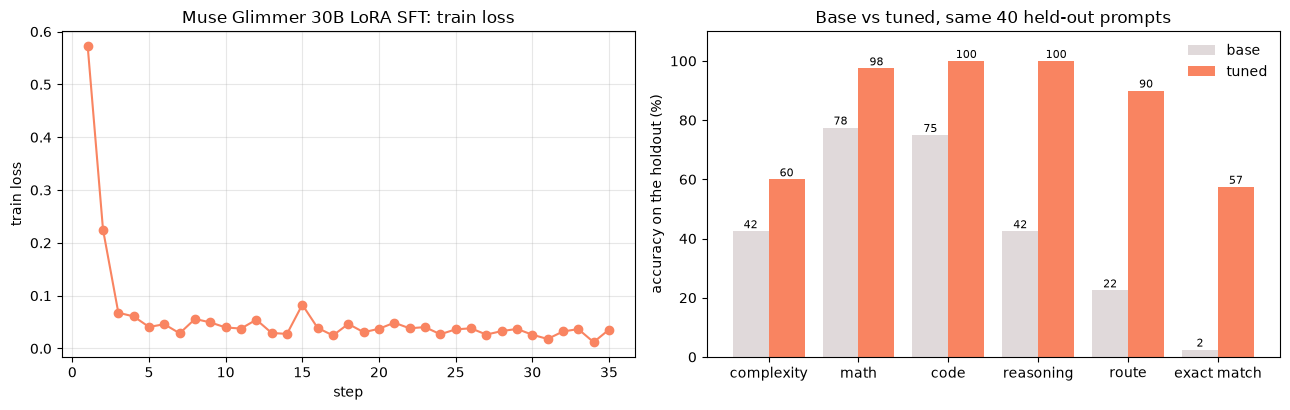

In [12]:
# summary.json (written by the starter): base/tuned exact match + per-field accuracy, and a paired McNemar test.
base_r, tuned_r = summary["base"], summary["tuned"]
fields = list(base_r["field_accuracy"])
print(f"route accuracy (the decision): {base_r['field_accuracy'].get('route', float('nan')):.1%} -> "
      f"{tuned_r['field_accuracy'].get('route', float('nan')):.1%}")
print(f"exact match (all fields):      {base_r['exact_match']:.1%} -> {tuned_r['exact_match']:.1%}")
print(f"McNemar (paired, exact match): p = {summary['paired']['p_value']:.3g} "
      f"({summary['paired']['only_tuned_correct']} fixed, {summary['paired']['only_base_correct']} broken)")
print(f"unterminated answers: base {base_r['unterminated']}, tuned {tuned_r['unterminated']}")

metrics = [json.loads(l) for l in (LOG_DIR / "metrics.jsonl").read_text().splitlines() if l.strip()]
steps = [m for m in metrics if "loss" in m and "step" in m]
base_preds = (LOG_DIR / "predictions_base.jsonl").read_text().splitlines()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot([m["step"] for m in steps], [m["loss"] for m in steps], marker="o", color="#F98461")
axes[0].set_xlabel("step")
axes[0].set_ylabel("train loss")
axes[0].set_title("Muse Glimmer 30B LoRA SFT: train loss")
axes[0].grid(True, alpha=0.3)

labels = fields + ["exact match"]
b = [base_r["field_accuracy"][f] * 100 for f in fields] + [base_r["exact_match"] * 100]
t = [tuned_r["field_accuracy"][f] * 100 for f in fields] + [tuned_r["exact_match"] * 100]
x = np.arange(len(labels))
axes[1].bar(x - 0.2, b, 0.4, label="base", color="#E0D9DA")
axes[1].bar(x + 0.2, t, 0.4, label="tuned", color="#F98461")
for xi, (bv, tv) in enumerate(zip(b, t)):
    axes[1].text(xi - 0.2, bv + 1, f"{bv:.0f}", ha="center", fontsize=8)
    axes[1].text(xi + 0.2, tv + 1, f"{tv:.0f}", ha="center", fontsize=8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylim(0, 110)
axes[1].set_ylabel("accuracy on the holdout (%)")
axes[1].set_title(f"Base vs tuned, same {len(base_preds)} held-out prompts")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

In [13]:
# Where did training change the answer? One row per held-out prompt.
base = [json.loads(l) for l in (LOG_DIR / "predictions_base.jsonl").read_text().splitlines() if l.strip()]
tuned = [json.loads(l) for l in (LOG_DIR / "predictions_tuned.jsonl").read_text().splitlines() if l.strip()]

cmp = pd.DataFrame({
    "gold_route": [pick_of(parse_json(r["gold"])) for r in base],
    "base_route": [pick_of(parse_json(r["answer_text"])) for r in base],
    "tuned_route": [pick_of(parse_json(r["answer_text"])) for r in tuned],
    "base_exact": [r["exact"] for r in base],
    "tuned_exact": [r["exact"] for r in tuned],
    "base_valid_json": [parse_json(r["answer_text"]) is not None for r in base],
    "tuned_valid_json": [parse_json(r["answer_text"]) is not None for r in tuned],
})
print(cmp[["base_valid_json", "tuned_valid_json", "base_exact", "tuned_exact"]].mean().round(3).to_string())
print("\nroute confusion, tuned (rows = gold, cols = predicted):")
display(pd.crosstab(cmp["gold_route"], cmp["tuned_route"].fillna("no answer")))
print("\nexamples training fixed:")
for i in cmp.index[(~cmp.base_exact) & (cmp.tuned_exact)][:3]:
    print(f"  gold  {base[i]['gold']}\n  base  {base[i]['answer_text'][:160]}\n  tuned {tuned[i]['answer_text'][:160]}\n")

base_valid_json     0.800
tuned_valid_json    1.000
base_exact          0.025
tuned_exact         0.575

route confusion, tuned (rows = gold, cols = predicted):


tuned_route,big,small
gold_route,,
big,30,3
small,1,6



examples training fixed:
  gold  {"complexity": 2, "math": true, "code": false, "reasoning": true, "route": "big model"}
  base  {"complexity":2,"math":true,"code":false,"reasoning":true,"route":"small model"}
  tuned {"complexity": 2, "math": true, "code": false, "reasoning": true, "route": "big model"}

  gold  {"complexity": 2, "math": true, "code": false, "reasoning": true, "route": "big model"}
  base  {"complexity": 2, "math": true, "code": false, "reasoning": true, "route": "small model"}
  tuned {"complexity": 2, "math": true, "code": false, "reasoning": true, "route": "big model"}

  gold  {"complexity": 2, "math": true, "code": false, "reasoning": true, "route": "big model"}
  base  {"complexity": 2, "math": true, "code": false, "reasoning": true, "route": "small model"}
  tuned {"complexity": 2, "math": true, "code": false, "reasoning": true, "route": "big model"}



## Use it: deploy the tuned router

Trained LoRAs can't run on serverless inference, so the tuned model goes on an **on-demand deployment** (live merge: the LoRA is merged into the base weights at deploy time, so there's no inference overhead). Deployments bill per GPU-hour while replicas run and take a while to come up, so **create this before the session** and delete it at the end.

In [14]:
TUNED_MODEL = f"accounts/{ACCOUNT_ID}/models/muse-starter-sl-{SL_RUN}"
DEPLOYMENT_ID = os.environ.get("DEPLOYMENT_ID", "muse-router-demo")
ROUTER_MODEL = f"accounts/{ACCOUNT_ID}/deployments/{DEPLOYMENT_ID}"

firectl("deployment-shape-version", "match", "--model", TUNED_MODEL)
firectl("deployment", "create", TUNED_MODEL, "--deployment-shape", "default",
         "--deployment-id", DEPLOYMENT_ID, "--min-replica-count", "1", "--wait", check=False)
print("inference model id (not the LoRA path):", ROUTER_MODEL)


$ firectl -a pyroworks --api-key *** deployment-shape-version match --model accounts/pyroworks/models/muse-starter-sl-router-sl-20261029-110353
2026/10/29 11:13:06 There are updates available.
	Current version: 1.8.21
	Latest version: 1.8.22

	To upgrade to the latest version, run
  	$ firectl upgrade

	
SHAPE NAME (version-id)                                                               BASE MODEL                                  GPUS  ACCELERATOR        PRECISION  PRESET TYPE
accounts/fireworks/deploymentShapes/dkuwotf7 (vtcy28lv)                               accounts/fireworks/models/muse-glimmer-30b  1     NVIDIA_H200_141GB  BF16       PRESET_TYPE_UNSPECIFIED
accounts/fireworks/deploymentShapes/w49lad6x (gcz9tcx2)                               accounts/fireworks/models/muse-glimmer-30b  1     NVIDIA_B300_288GB  BF16       PRESET_TYPE_UNSPECIFIED
accounts/fireworks/deploymentShapes/muse-glimmer-30b-decision-engine-b200 (ch5gdqk6)  accounts/fireworks/models/muse-glimmer-30b  1     

## The payoff: a trained router in front of two models

Prompt → **tuned Muse Glimmer** decides small or big → **DeepSeek V4.1 Flash** (small) or **Muse Spark Open** (big) answers.

In [15]:
glob_client = OpenAI(base_url="https://api.fireworks.ai/inference/v1", api_key=FIREWORKS_API_KEY)
us_client = OpenAI(base_url="https://us.api.fireworks.ai/inference/v1", api_key=FIREWORKS_API_KEY)

# LoRA model ids are not serverless-callable. Hit the on-demand deployment resource.
DEPLOYMENT_ID = os.environ.get("DEPLOYMENT_ID", "muse-router-demo")
ROUTER_MODEL = f"accounts/{ACCOUNT_ID}/deployments/{DEPLOYMENT_ID}"
print("router endpoint:", ROUTER_MODEL)

TARGETS = {
    "small": (glob_client, "accounts/fireworks/models/deepseek-v4p1-flash", 0.30, 1.20),
    "big":   (us_client,   "accounts/fireworks/models/muse-spark-open",     1.25, 4.25),
}

def route(prompt):
    msgs = ([{"role": "system", "content": ROUTER_SYSTEM}] if ROUTER_SYSTEM else []) + [{"role": "user", "content": prompt}]
    r = glob_client.chat.completions.create(model=ROUTER_MODEL, messages=msgs, max_tokens=128, temperature=0.0)
    raw = r.choices[0].message.content
    return raw, pick_of(parse_json(raw)) or "big"    # unsure -> the safe default

def answer(prompt):
    t0 = time.perf_counter()
    raw, pick = route(prompt)
    t_route = time.perf_counter() - t0
    client, model, pin, pout = TARGETS[pick]
    r = client.chat.completions.create(model=model, messages=[{"role": "user", "content": prompt}], max_tokens=1024)
    u = r.usage
    cost = ((u.prompt_tokens or 0) * pin + (u.completion_tokens or 0) * pout) / 1e6
    return {"router_json": raw, "pick": pick, "model": model.split("/")[-1], "route_s": round(t_route, 2),
            "cost_usd": round(cost, 6), "answer": (r.choices[0].message.content or "")[:200]}

DEMO_PROMPTS = [
    "What's the capital of Turkey?",
    "Convert 72 Fahrenheit to Celsius.",
    "Design a sharded rate limiter for a multi-region API gateway and explain the failure modes.",
    "Prove that there are infinitely many primes, then generalize the argument to primes of the form 4k+3.",
]
for p in DEMO_PROMPTS:
    out = answer(p)
    print(f"\n> {p}\n  router: {out['router_json']}\n  -> {out['pick']} ({out['model']}), "
          f"decide {out['route_s']}s, ${out['cost_usd']}\n  {out['answer']}")


router endpoint: accounts/pyroworks/deployments/muse-router-demo

> What's the capital of Turkey?
  router: {"complexity": 1, "math": false, "code": false, "reasoning": false, "route": "small model"}
  -> small (deepseek-v4p1-flash), decide 3.27s, $5.1e-05
  The capital of Turkey is **Ankara**.

> Convert 72 Fahrenheit to Celsius.
  router: {"complexity": 2, "math": true, "code": false, "reasoning": true, "route": "big model"}
  -> big (muse-spark-open), decide 2.81s, $0.002165
  72°F is **22.2°C**

Formula: `(72 - 32) × 5/9 = 22.22°C`

> Design a sharded rate limiter for a multi-region API gateway and explain the failure modes.
  router: {"complexity": 4, "math": false, "code": false, "reasoning": true, "route": "big model"}
  -> big (muse-spark-open), decide 2.97s, $0.004555
  

> Prove that there are infinitely many primes, then generalize the argument to primes of the form 4k+3.
  router: {"complexity": 4, "math": true, "code": false, "reasoning": true, "route": "big model"}
  -> b

## Clean up

Delete the deployment (this stops billing; the trained model stays in your account and can be redeployed any time), then remove the training jobs and models for each run ID.

In [16]:
firectl("deployment", "delete", DEPLOYMENT_ID, "--wait", check=False)
# Uncomment to remove the serverless job/model too:
# starter("cleanup", "--run-id", SL_RUN, check=False)


$ firectl -a pyroworks --api-key *** deployment delete muse-router-demo --wait
2026/10/29 11:14:10 There are updates available.
	Current version: 1.8.21
	Latest version: 1.8.22

	To upgrade to the latest version, run
  	$ firectl upgrade

	
2026/10/29 11:14:13 Failed to execute: rpc error: code = FailedPrecondition desc = deployment has received inference requests in the last hour, pass --ignore-checks to skip this check


'2026/10/29 11:14:10 There are updates available.\n\tCurrent version: 1.8.21\n\tLatest version: 1.8.22\n\n\tTo upgrade to the latest version, run\n  \t$ firectl upgrade\n\n\t\n2026/10/29 11:14:13 Failed to execute: rpc error: code = FailedPrecondition desc = deployment has received inference requests in the last hour, pass --ignore-checks to skip this check\n'

## Takeaways

- **Free first fine-tune.** Muse Glimmer 30B LoRA SFT is free until Nov 30. A few hundred clean rows are enough for a first signal.
- **Public HF data, no upload.** Build chat JSONL from Hugging Face locally; Serverless Training streams it from your process (works when `datasets.upload` is disabled).
- **Read the data, then the rendered example**, before you launch.
- **Loss is not accuracy.** Compare base and tuned on held-out rows with the same decoding settings.
- **Your own data:** the same starter takes chat JSONL (`{"messages": [system, user, assistant]}`). `prepare` validates every row and refuses malformed ones rather than silently dropping them.
- **Next step: RL.** When you can score outputs but don't have perfect labels, the cookbook's serverless RL loop runs on Muse Glimmer too. See [Serverless Training](https://docs.fireworks.ai/fine-tuning/training-api/serverless).
